In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RAIZ_PROJETO = Path("..").resolve()
if str(RAIZ_PROJETO / "src") not in sys.path:
    sys.path.append(str(RAIZ_PROJETO / "src"))

from perceptron_pp import Perceptron, metricas, visualizacao

In [2]:
caminho_dados = RAIZ_PROJETO / "data" / "data120262.txt"

if not caminho_dados.exists():
    raise FileNotFoundError(f"arquivo não encontrado em: {caminho_dados}")

dados = np.load(caminho_dados)

# remodelagem de (m, 1, 3) para (m, 3) caso precise
if dados.ndim == 3:
    dados = dados.reshape(-1, 3)

X = dados[:, :2]  # atributos x1, x2
y = dados[:, 2]   # tótulo yd (0 ou 1)

print(f"Dimensões de X: {X.shape}, Dimensões de y: {y.shape}")

Dimensões de X: (1000, 2), Dimensões de y: (1000,)


In [6]:
# Configurações

etas = [0.4, 0.1, 0.01]
intervalos = [(-100, 100), (-0.5, 0.5)]
n_repeticoes = 10
max_epocas = 10_000  # limite de segurança caso o conjunto não seja linearmente separável

resultados = []

for eta in etas:                          # 3 valores
    for intervalo in intervalos:          # x 2 valores = 6 configurações
        for rep in range(n_repeticoes):   # x 10 repetições = 60 execuções
            modelo = Perceptron(eta=eta, intervalo_pesos=intervalo, theta=0.0, rng=rep)
            modelo.fit(X, y, max_epocas=200, verbose=False)

            resultados.append({
                "eta": eta,
                "intervalo": str(intervalo),  # string evita erro ao comparar a coluna com tuplas
                "repeticao": rep,
                "ajustes": modelo.n_ajustes_,
                "epocas": modelo.n_epocas_,
                "convergiu": modelo.convergiu_,
            })

df = pd.DataFrame(resultados)
print(f"Execuções: {len(df)} | Todas convergiram: {df['convergiu'].all()}")
df.head(10)

Execuções: 60 | Todas convergiram: False


,eta,intervalo,repeticao,ajustes,epocas,convergiu
0,0.4,"(-100, 100)",0,9431,200,False
1,0.4,"(-100, 100)",1,9491,200,False
2,0.4,"(-100, 100)",2,9451,200,False
3,0.4,"(-100, 100)",3,9505,200,False
4,0.4,"(-100, 100)",4,9483,200,False
5,0.4,"(-100, 100)",5,9504,200,False
6,0.4,"(-100, 100)",6,9425,200,False
7,0.4,"(-100, 100)",7,9484,200,False
8,0.4,"(-100, 100)",8,9441,200,False
9,0.4,"(-100, 100)",9,9478,200,False


In [7]:
print(metricas.tabela_resumo(df))

+---------------------+--------------------+------------------+------------+------------+
| Taxa de Aprendizado | Intervalo de Pesos |   Qtde Ajustes   | Min Épocas | Max Épocas |
+---------------------+--------------------+------------------+------------+------------+
|       η = 0.4       |    (-100, 100)     | 9469.30 ± 29.80  |    200     |    200     |
|       η = 0.4       |    (-0.5, 0.5)     | 9493.60 ± 19.46  |    200     |    200     |
|       η = 0.1       |    (-100, 100)     | 9490.30 ± 21.33  |    200     |    200     |
|       η = 0.1       |    (-0.5, 0.5)     | 9481.70 ± 32.68  |    200     |    200     |
|       η = 0.01      |    (-100, 100)     | 9528.90 ± 124.75 |    200     |    200     |
|       η = 0.01      |    (-0.5, 0.5)     | 9499.80 ± 14.76  |    200     |    200     |
+---------------------+--------------------+------------------+------------+------------+


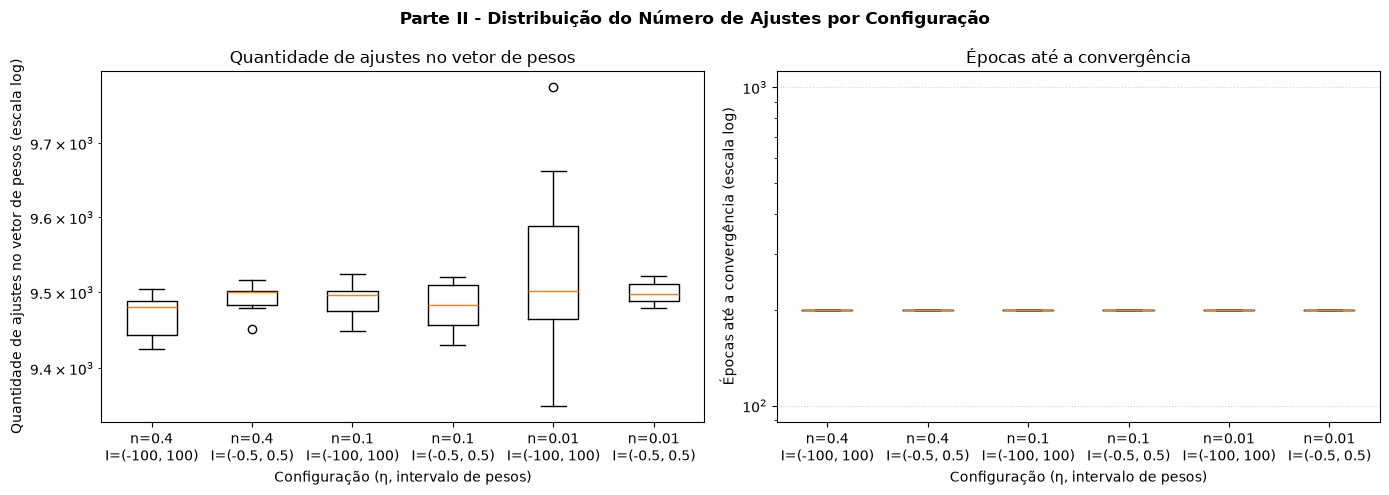

In [8]:
PASTA_RESULTADOS = RAIZ_PROJETO / "resultados"
PASTA_RESULTADOS.mkdir(exist_ok=True)

fig, axes = visualizacao.plot_boxplots_experimentos(df)
fig.savefig(PASTA_RESULTADOS / "parte2_boxplots.png", dpi=150, bbox_inches="tight")
plt.show()